# Notebook 3 — Regresión de la nota media del 2º semestre

Predecimos la variable continua `nota_media_2sem` a partir de las características
del estudiante y su desempeño en el 1er semestre, evitando data leakage.

La lógica está en `src/regresion.py`.

## Modelos

Probamo modelos desde lo más simple a lo no lineal:

- **Regresión lineal simple** (sin regularizar) — baseline.
- **Ridge** (L2) — regulariza estabilizando coeficientes
- **Lasso** (L1) — fuerza coeficientes a cero, haciendo selección automática
  de variables.
- **ElasticNet** (L1+L2) — combinación de ambas.
- **SVR lineal** — alternativa con pérdida `epsilon`-insensible.
- **SVR RBF** — kernel trick, mapea a dimensión infinita
- **Random Forest Regressor** — no lineal, robusto a multicolinealidad, con
  `feature_importances` interpretables.

## Consideraciones en el preprocesado

**Anti data-leakage.** El dataset de regresión se construyó eliminando todas
las variables del 2º semestre distintas del target. `cargar_datos` verifica
esta propiedad y aborta si encuentra alguna columna que contamine.

**Exclusión de abandonos.** También se excluyeron los alumnos con nota 0.0
en 1er o 2º semestre. Un 0.0 en este contexto no se ha considerado como rendimiento bajo, sino
 como abandono, Mezclarlo con notas reales crearía una distribución
bimodal que ningún regresor continuo podría ajustar correctamente.

## 0. Configuración

In [10]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import regresion
from configuracion import (
    REGRESION_TRAIN, REGRESION_TEST,
    DIAGNOSTICO_PREFIX, FEATURE_IMPORTANCE_REG,
    RESUMEN_REGRESION, PREDICCIONES_REGRESION,
    RESULTS_DIR,
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f'Train: {REGRESION_TRAIN}')
print(f'Test:  {REGRESION_TEST}')

Train: C:\Users\mb6ja\Downloads\proyecto\data\processed\datos_limpios_regresion_train.csv
Test:  C:\Users\mb6ja\Downloads\proyecto\data\processed\datos_limpios_regresion_test.csv


## 1. Carga de datos

`cargar_datos` aborta` si detecta variables del 2º semestre
distintas del target en las features para asegurar que no se produce data-leakage

In [2]:
X_train, y_train, X_test, y_test = regresion.cargar_datos(
    str(REGRESION_TRAIN), str(REGRESION_TEST),
)
print(f'Train: {X_train.shape[0]} registros × {X_train.shape[1]} features')
print(f'Test:  {X_test.shape[0]} registros')
print(f'\nTarget nota_media_2sem:')
print(f'  rango train: {y_train.min():.2f} a {y_train.max():.2f}')
print(f'  media train: {y_train.mean():.2f}')
print(f'  std train:   {y_train.std():.2f}')
print('\nComprobación anti-leakage: OK.')

Train: 2750 registros × 29 features
Test:  688 registros

Target nota_media_2sem:
  rango train: 10.00 a 18.57
  media train: 12.75
  std train:   1.37

Comprobación anti-leakage: OK.


### 1.1 Distribución del target

Es importante visualizar el target antes de modelar para entender qué
estamos prediciendo y posteriormente comprobar que los resultados obtenidos son razonables.

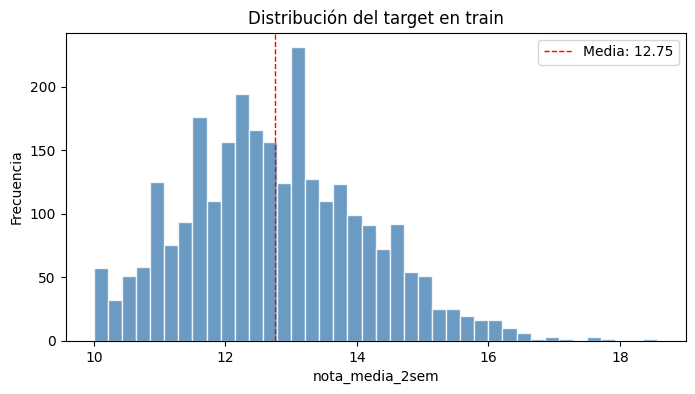

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_train, bins=40, color='steelblue', alpha=0.8, edgecolor='white')
ax.axvline(y_train.mean(), color='red', ls='--', lw=1, label=f'Media: {y_train.mean():.2f}')
ax.set_xlabel('nota_media_2sem')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución del target en train')
ax.legend()
plt.show()

Como casi todas las notas son muy parecidas (están amontonadas entre 10 y 18), es muy difícil 
que el modelo acierte el número exacto. No es que todos los modelos sean sea malos, es que al variar los datos 
tan poco, cualquier pequeño fallo parece un error gigante. Por eso, aunque el modelo sea 
bueno, nunca tendremos una puntuación de precisión ($R^2$) perfecta.

## 2. Preprocesador

Igual que en clasificación: `StandardScaler` para numéricas y `OneHotEncoder` para categóricas. Todo dentro de un
`Pipeline` para que el `fit` sólo vea el fold de entrenamiento en cada
iteración de la CV.

In [4]:
preprocesador = regresion.construir_preprocesador(X_train)
cols_num = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cols_cat = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print(f'Numéricas   ({len(cols_num)}): {cols_num}')
print(f'\nCategóricas ({len(cols_cat)}): {cols_cat}')

Numéricas   (13): ['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']

Categóricas (16): ['estado_civil', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional']


## 3. Definición de modelos y grids

In [5]:
modelos = regresion.definir_modelos_y_grids(preprocesador)
for nombre, (_, grid) in modelos.items():
    n_combos = int(np.prod([len(v) for v in grid.values()])) if grid else 1
    print(f'  {nombre:28s}  {n_combos:3d} combinaciones')

  Regresion_lineal_simple         1 combinaciones
  Ridge                           7 combinaciones
  Lasso                           7 combinaciones
  ElasticNet                     20 combinaciones
  SVR_linear                      9 combinaciones
  SVR_RBF                        36 combinaciones
  RandomForest                   36 combinaciones


## 4. Entrenamiento con validación cruzada

`KFold(5)` con `scoring='r2'`. Por cada combinación se entrenan 5 modelos.
El SVR-RBF es el más lento ($O(n^2)$), puede tardar unos minutos.

In [7]:
resultados = regresion.entrenar_modelos(modelos, X_train, y_train, verbose=0)


  Entrenando: Regresion_lineal_simple
  Mejor R² (CV):   -2295310619960513280.0000
  Mejores params:  {}

  Entrenando: Ridge
  Mejor R² (CV):   0.4857
  Mejores params:  {'reg__alpha': 100}

  Entrenando: Lasso
  Mejor R² (CV):   0.4858
  Mejores params:  {'reg__alpha': 0.01}

  Entrenando: ElasticNet
  Mejor R² (CV):   0.4884
  Mejores params:  {'reg__alpha': 0.01, 'reg__l1_ratio': 0.3}

  Entrenando: SVR_linear
  Mejor R² (CV):   0.4806
  Mejores params:  {'reg__C': 0.1, 'reg__epsilon': 0.5}

  Entrenando: SVR_RBF
  Mejor R² (CV):   0.5140
  Mejores params:  {'reg__C': 1, 'reg__epsilon': 0.5, 'reg__gamma': 'scale'}

  Entrenando: RandomForest
  Mejor R² (CV):   0.5143
  Mejores params:  {'reg__max_depth': 10, 'reg__min_samples_leaf': 3, 'reg__n_estimators': 500}


## 5. Evaluación en test

Métricas reportadas:

- **R²**: proporción de varianza explicada (0 = modelo constante, 1 = perfecto).
- **RMSE**: error cuadrático medio, penaliza errores grandes.
- **MAE**: error absoluto medio, más interpretable directamente en la escala
  de las notas.

In [11]:
df_resumen = regresion.evaluar_en_test(resultados, X_test, y_test, path_resumen_csv=str(RESUMEN_REGRESION))

  Regresion_lineal_simple    R²=0.5390  RMSE=0.9425  MAE=0.7375
  Ridge                      R²=0.5468  RMSE=0.9345  MAE=0.7329
  Lasso                      R²=0.5380  RMSE=0.9435  MAE=0.7397
  ElasticNet                 R²=0.5460  RMSE=0.9353  MAE=0.7339
  SVR_linear                 R²=0.5446  RMSE=0.9368  MAE=0.7326
  SVR_RBF                    R²=0.5617  RMSE=0.9190  MAE=0.7110
  RandomForest               R²=0.5520  RMSE=0.9291  MAE=0.7249

  RESUMEN COMPARATIVO (ordenado por R² en test)
                 modelo         r2_cv  r2_test  rmse_test  mae_test                                                               mejores_params
                SVR_RBF  5.140428e-01 0.561673   0.919023  0.711024                    {'reg__C': 1, 'reg__epsilon': 0.5, 'reg__gamma': 'scale'}
           RandomForest  5.142646e-01 0.552050   0.929056  0.724889 {'reg__max_depth': 10, 'reg__min_samples_leaf': 3, 'reg__n_estimators': 500}
                  Ridge  4.857377e-01 0.546795   0.934489  0.732867 

### 5.1 Tabla comparativa

In [12]:
df_resumen[['modelo', 'r2_cv', 'r2_test', 'rmse_test', 'mae_test']]

,modelo,r2_cv,r2_test,rmse_test,mae_test
0,SVR_RBF,5.140428e-01,0.561673,0.919023,0.711024
1,RandomForest,5.142646e-01,0.552050,0.929056,0.724889
2,Ridge,4.857377e-01,0.546795,0.934489,0.732867
3,ElasticNet,4.884171e-01,0.545988,0.935322,0.733920
4,SVR_linear,4.806341e-01,0.544576,0.936775,0.732609
5,Regresion_lineal_simple,-2.295311e+18,0.538977,0.942515,0.737526
6,Lasso,4.858163e-01,0.538037,0.943476,0.739669


### 5.2 Interpretación comparativa


- Si Regresion_Lineal_Simple, Ridge y SVR RBF rinden de forma parecida, indica que la relación
  `target - features` es lineal: no hay no linealidades que el kernel pueda explotar.
- Si Lasso iguala o supera a Ridge con muchos coeficientes a cero, hay
  redundancia alta entre variables (consistente con la multicolinealidad
  entre las variables del 1er semestre).
- Si Random Forest gana claramente, hay estructura no lineal relevante.

## 6. Diagnóstico gráfico del mejor modelo

Para el modelo con mayor R² en test, visualizamos:

- **Predicho vs real**: idealmente los puntos caen sobre la diagonal.
- **Residuos vs predicho**: idealmente una nube sin estructura alrededor de 0.
  Cualquier patrón (curvatura, embudo, bandas) indica que el modelo está
  perdiendo señal.

Mejor modelo en test: SVR_RBF


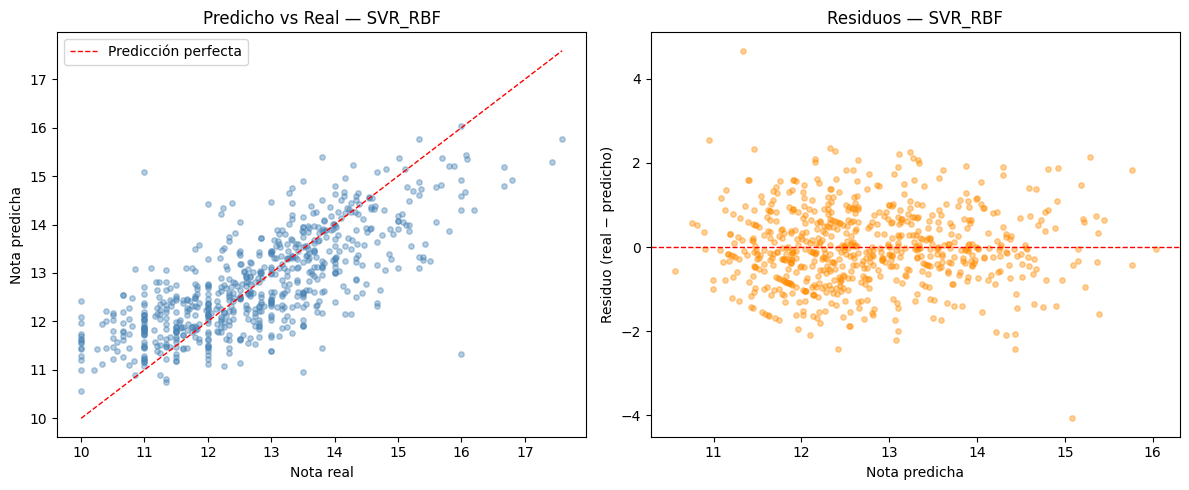

In [13]:
nombre_mejor = df_resumen.iloc[0]['modelo']
print(f'Mejor modelo en test: {nombre_mejor}')

fig_diag = regresion.diagnostico_grafico(
    nombre_mejor, resultados[nombre_mejor], X_test, y_test,
    path_fig=str(DIAGNOSTICO_PREFIX) + f'{nombre_mejor}.png')
plt.show()

**Lectura de los gráficos:**

- La nube de predicciones es **más estrecha que la diagonal** en los
  extremos (*shrinkage por averaging*: al promediar
  muchos árboles, las predicciones se encogen hacia la media). Esto se
  traduce en que **los mejores estudiantes quedan subestimados** y los peores sobreestimados.
- La distribución de los residuos es una nube uniforme que no sigue ninguna distribución aparente 
  por lo que estamos ante un caso de homocedasticidad, que es justamente lo que buscamos.

Con un modelo lineal (Ridge, Lasso) estos patrones suelen ser menos marcados
porque no hay averaging.

### 6.1 Diagnóstico del Lasso para comparar

Conviene comparar el diagnóstico del modelo no lineal (el que mejor se ajusta a este problema) con el de un
modelo lineal para ver el efecto del shrinkage.

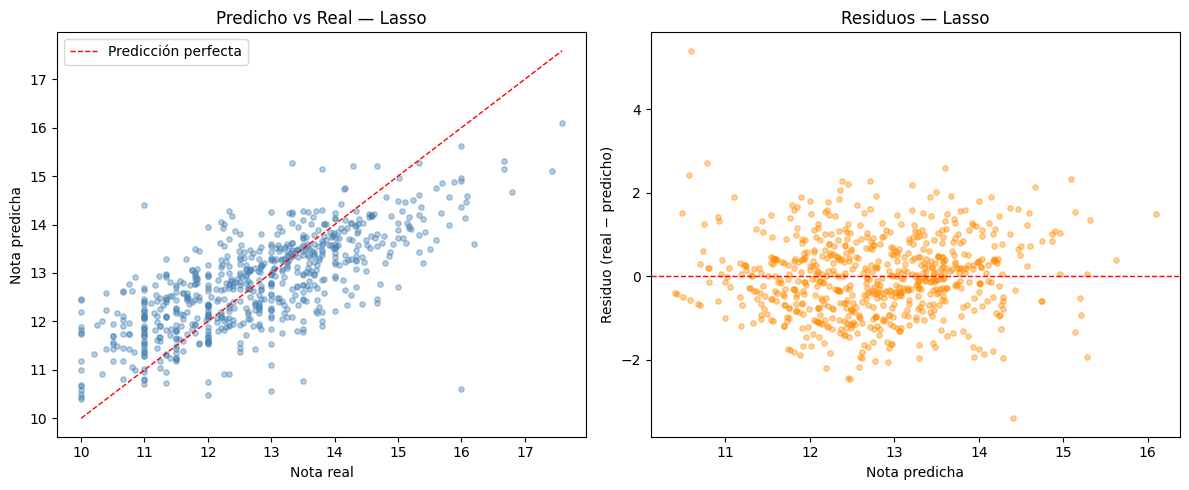

In [14]:
if 'Lasso' in resultados and nombre_mejor != 'Lasso':
    fig_lasso = regresion.diagnostico_grafico(
        'Lasso', resultados['Lasso'], X_test, y_test,
        path_fig=str(DIAGNOSTICO_PREFIX) + 'Lasso.png',
    )
    plt.show()

## 7. Interpretabilidad

### 7.1 Coeficientes del Lasso

Lasso fuerza coeficientes a cero, lo que ofrece una selección automática de
las variables más informativas. El signo indica la dirección del efecto,
interpretable sobre variables ya estandarizadas.

In [15]:
df_coefs = regresion.coeficientes_lasso(resultados['Lasso'], top_n=15)
df_coefs


  Lasso: 24 / 109 variables con coef != 0


,variable,coeficiente
0,nota_media_1sem,0.777701
1,asignaturas_1sem_aprobadas,0.310782
2,curso_enfermeria,0.189678
3,curso_educacion_basica,-0.181041
4,cualificacion_previa_superior,0.180025
5,asignaturas_1sem_matriculadas,-0.122614
6,asignaturas_1sem_convalidadas,-0.102628
7,curso_diseno_de_comunicacion,-0.085281
8,curso_gestion_de_publicidad_y_marketing,0.082675
9,nota_admision,0.068813


### 7.2 Importancia de variables del Random Forest

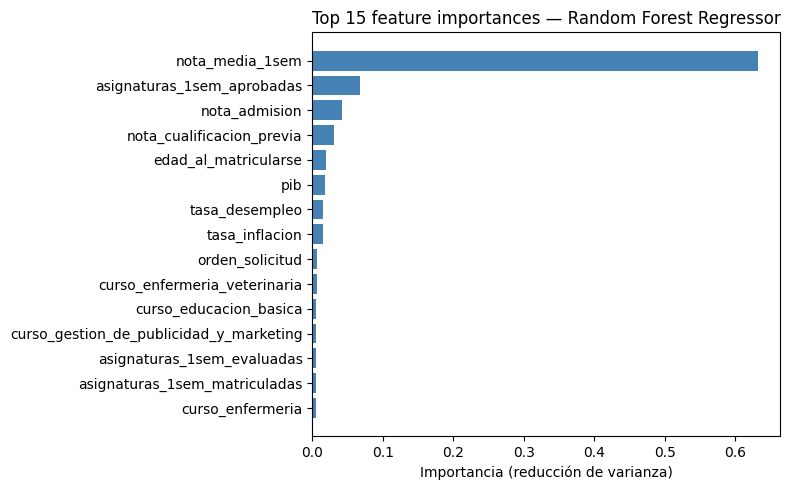

,variable,importancia
0,nota_media_1sem,0.631752
1,asignaturas_1sem_aprobadas,0.068242
2,nota_admision,0.042138
3,nota_cualificacion_previa,0.031106
4,edad_al_matricularse,0.019360
5,pib,0.018320
6,tasa_desempleo,0.014953
7,tasa_inflacion,0.014427
8,orden_solicitud,0.006366
9,curso_enfermeria_veterinaria,0.006260


In [16]:
df_imp, fig_imp = regresion.importancia_rf(
    resultados['RandomForest'],
    top_n=15,
    path_fig=str(FEATURE_IMPORTANCE_REG))

plt.show()
df_imp

### 7.3 Interpretación

**Variable dominante.** `nota_media_1sem`. Esto es esperado ya que el rendimiento académico suele ser consistente de una semestre a otro.

**Matiz sobre la importancia de Gini.** En presencia de multicolinealidad
alta (ej. entre `asignaturas_1sem_aprobadas` y `nota_media_1sem`, que
están fuertemente correladas), el RF encuentra que una de ellas resume la información y las
demás quedan con importancia baja no porque no sean informativas, sino
porque son redundantes (explican lo mismo).

**Coincidencia Lasso y RF.** Si las top variables de ambas listas coinciden, tenemos evidencia robusta de su relevancia.
Si difieren, el RF probablemente está capturando efectos no lineales o
interacciones entre variables que el lasso no ha capturado.

## 8. Guardar predicciones del mejor modelo

In [17]:
preds = pd.DataFrame({
    'y_real': y_test.values,
    'y_pred': resultados[nombre_mejor].predict(X_test)})

preds.to_csv(PREDICCIONES_REGRESION, index=False)
print(f'Guardado: {PREDICCIONES_REGRESION}')
preds.head()

Guardado: C:\Users\mb6ja\Downloads\proyecto\results\predicciones_regresion.csv


,y_real,y_pred
0,13.125556,13.794606
1,13.500000,13.740106
2,11.000000,12.054994
3,13.250000,13.035879
4,10.800000,12.474605


## 9. Conclusiones

- El R² obtenido es relativamente bajo porque intentamos predecir una
  nota individual sólo a partir
  de información previa. Esto es consistente con que el target tiene una
  desviación típica pequeña (1.4) en un rango estrecho.
- El predictor dominante es el **rendimiento del 1er semestre**. Los modelos
  lineales regularizados y el RF coinciden en esta conclusión.
- Los modelos basados en árboles muestran **shrinkage** hacia la media del
  target: subestiman a los mejores estudiantes y
  sobreestiman a los peores.